# Rebase Grid API: day-ahead price examples

A tour of the `RebaseGridClient` for price-prediction work: find series, read long histories, compare zones, and line prices up against their fundamental drivers.

Needs `REBASE_GRID_API_KEY` in `.env` (see README). All API times are UTC.

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from energy_price_predictor import RebaseGridClient

grid = RebaseGridClient()
print(grid.me())

{'email': 'christian@aboutenergy.co.uk', 'name': 'Christian Pilling', 'scope': 'public'}


Plot styling: thin lines, recessive grid and axes, and a fixed categorical colour order so each zone keeps its colour across charts.

In [8]:
SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']  # categorical slots 1-4, fixed order
BLUE_LIGHT, BLUE, BLUE_DARK = '#86b6ef', '#2a78d6', '#184f95'
INK, INK_MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list(
    'seq_blue', ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
)

plt.rcParams.update({
    'figure.figsize': (11, 4.5),
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': INK_MUTED,
    'axes.labelcolor': INK_MUTED,
    'axes.titlelocation': 'left',
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.color': GRID,
    'grid.linewidth': 0.8,
    'xtick.color': INK_MUTED,
    'ytick.color': INK_MUTED,
    'lines.linewidth': 1.6,
    'legend.frameon': False,
})

## 1. Discover

The entity tree lists every country, price zone and area. The day-ahead price has the same name in every zone: `price.day_ahead.day_ahead_auction_price`.

In [9]:
entities = grid.entities()
price_zones = entities[entities['kind'] == 'price_zone']
print(f'{len(price_zones)} price zones, e.g.', ', '.join(price_zones['id'].head(12)))

PRICE = 'price.day_ahead.day_ahead_auction_price'
names = grid.timeseries_names('DE-LU', category='price', provider='entsoe')
names[names['name'].str.startswith('price.day_ahead')]

55 price zones, e.g. AL, AD, AT, BE, BA, BG, HR, CY, CZ, DK-DK1, DK-DK2, EE


,name,provider,data_type
0,price.day_ahead.day_ahead_auction_price,entsoe,price
1,price.day_ahead.day_ahead_auction_price.auctio...,entsoe,price


In [10]:
meta = grid.metadata('DE-LU', PRICE)
entsoe = grid.provider_metadata('DE-LU', PRICE, 'entsoe')
print('unit:', meta['unit'])
print('resolution history:', entsoe['resolution_history'])
print('extent:', entsoe['extent'])

unit: EUR/MWh
resolution history: [{'valid_from': '2018-09-30T22:00:00Z', 'resolution': 'PT1H'}, {'valid_from': '2025-09-30T22:00:00Z', 'resolution': 'PT15M'}]
extent: {'first': '2018-09-30T22:00:00Z', 'last': '2026-11-07T22:45:00Z'}


## 2. Long history

`values()` splits a multi-year range into windows of at most 100,000 points, so one call returns the whole history. The resolution changed from hourly to quarter-hourly in September 2026, so resample to hourly for a consistent series.

97,759 raw points -> 68,809 hourly


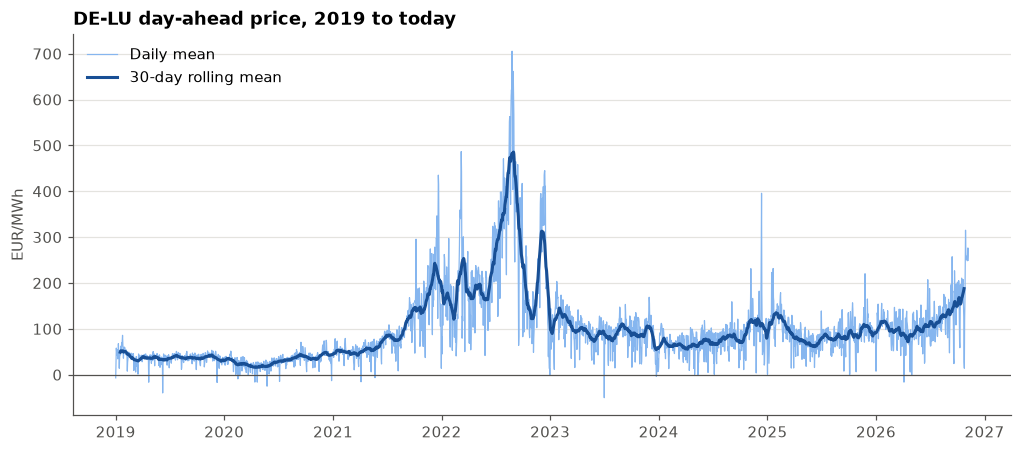

In [11]:
ZONE = 'DE-LU'
now = pd.Timestamp.now(tz='UTC').floor('D')

raw = grid.values(ZONE, PRICE, provider='entsoe', start='2019-01-01', end=now)
hourly_price = raw['value'].resample('h').mean()
print(f'{len(raw):,} raw points -> {len(hourly_price):,} hourly')

daily = hourly_price.resample('D').mean()
rolling = daily.rolling(30, center=True).mean()

fig, ax = plt.subplots()
ax.plot(daily.index, daily, color=BLUE_LIGHT, linewidth=0.8, label='Daily mean')
ax.plot(rolling.index, rolling, color=BLUE_DARK, linewidth=2, label='30-day rolling mean')
ax.axhline(0, color=INK_MUTED, linewidth=0.8)
ax.set_title(f'{ZONE} day-ahead price, 2019 to today')
ax.set_ylabel(meta['unit'])
ax.legend(loc='upper left')
plt.show()

## 3. Zones compared

The same series in four zones over the last 60 days. Colour follows the zone.

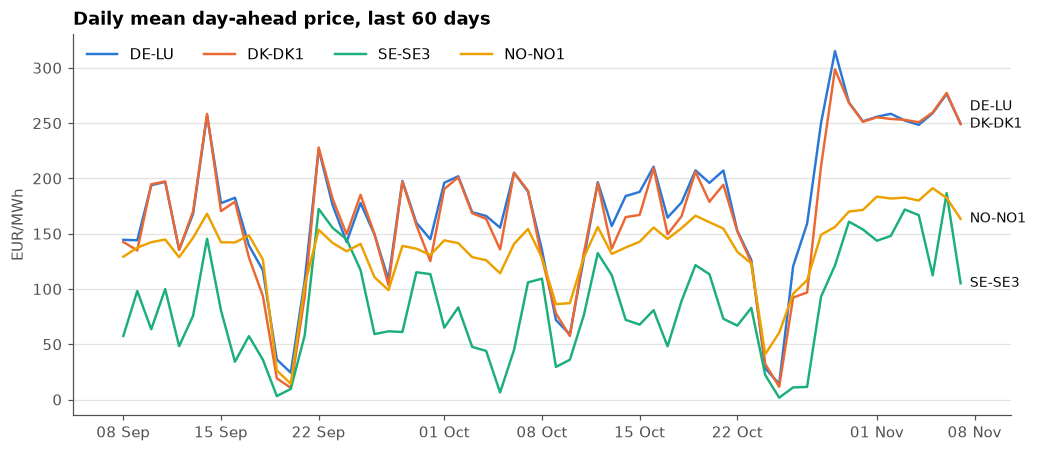

In [12]:
ZONES = ['DE-LU', 'DK-DK1', 'SE-SE3', 'NO-NO1']
start = now - pd.Timedelta(days=60)

zone_daily = pd.DataFrame({
    zone: grid.values(zone, PRICE, provider='entsoe', start=start, end=now)['value'].resample('D').mean()
    for zone in ZONES
})

def spread_labels(values, min_gap):
    """Nudge label heights apart so end-of-line labels do not overlap."""
    placed = {}
    for key in sorted(values, key=values.get):  # bottom to top
        placed[key] = max([values[key]] + [height + min_gap for height in placed.values()])
    return placed

fig, ax = plt.subplots()
for zone, color in zip(ZONES, SERIES_COLORS):
    ax.plot(zone_daily.index, zone_daily[zone], color=color, label=zone)

last_values = zone_daily.ffill().iloc[-1].to_dict()
label_heights = spread_labels(last_values, min_gap=0.05 * np.ptp(zone_daily.values[~np.isnan(zone_daily.values)]))
for zone in ZONES:
    ax.annotate(zone, (zone_daily.index[-1], label_heights[zone]), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=9, color=INK)
ax.set_title('Daily mean day-ahead price, last 60 days')
ax.set_ylabel('EUR/MWh')
ax.legend(loc='upper left', ncol=4)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.margins(x=0.06)
plt.show()

## 4. Shape of the day

Average price by hour of day (local time) and month over the last two years: solar pushes midday prices down in summer; the evening peak is highest in winter.

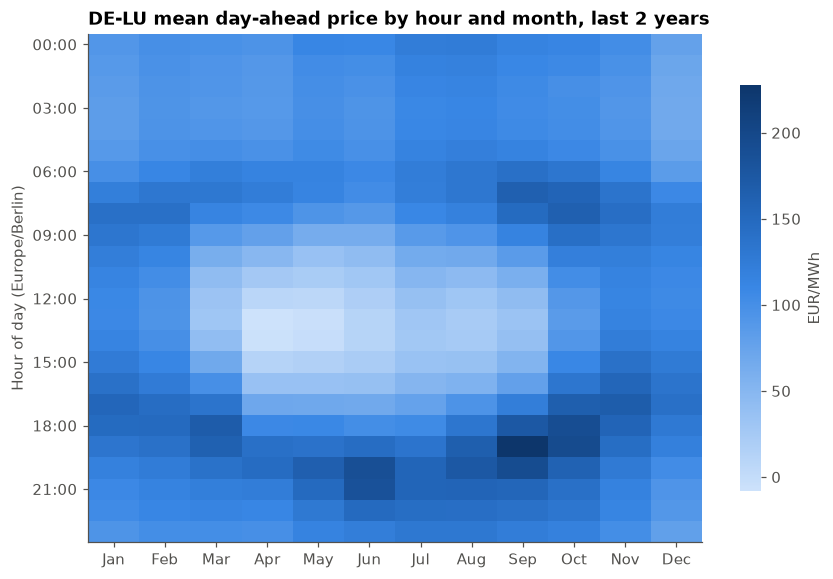

In [13]:
recent = hourly_price[hourly_price.index >= now - pd.DateOffset(years=2)].tz_convert('Europe/Berlin')
profile = (
    recent.to_frame('price')
    .assign(month=recent.index.month, hour=recent.index.hour)
    .pivot_table(index='hour', columns='month', values='price', aggfunc='mean')
)

fig, ax = plt.subplots(figsize=(9, 6))
image = ax.imshow(profile, aspect='auto', cmap=SEQUENTIAL_BLUE, origin='upper')
ax.grid(False)
ax.set_xticks(range(12), [pd.Timestamp(2000, m, 1).strftime('%b') for m in profile.columns])
ax.set_yticks(range(0, 24, 3), [f'{h:02d}:00' for h in range(0, 24, 3)])
ax.set_ylabel('Hour of day (Europe/Berlin)')
ax.set_title(f'{ZONE} mean day-ahead price by hour and month, last 2 years')
colorbar = fig.colorbar(image, ax=ax, label='EUR/MWh', shrink=0.8)
colorbar.outline.set_visible(False)
plt.show()

## 5. Price drivers

Day-ahead forecasts of load, wind and solar are published before the auction, so they are candidate features. Residual load (load minus wind and solar) is the demand left for dispatchable plants, and usually the strongest single driver of the price.

In [14]:
DRIVERS = {
    'load': 'consumption.load_forecast.day_ahead_total_load_forecast',
    'solar': 'production.forecast.solar_generation_forecast.day_ahead',
    'wind_onshore': 'production.forecast.wind_generation_forecast.onshore_day_ahead',
    'wind_offshore': 'production.forecast.wind_generation_forecast.offshore_day_ahead',
}
start = now - pd.DateOffset(years=1)

features = pd.DataFrame({
    label: grid.values(ZONE, name, provider='entsoe', start=start, end=now)['value'].resample('h').mean()
    for label, name in DRIVERS.items()
})
features['wind_solar'] = features[['solar', 'wind_onshore', 'wind_offshore']].sum(axis=1, min_count=1)
features['residual_load'] = features['load'] - features['wind_solar']
features['price'] = hourly_price
features = features.dropna()
features.describe().round(0)

,load,solar,wind_onshore,wind_offshore,wind_solar,residual_load,price
count,8727.0,8727.0,8727.0,8727.0,8727.0,8727.0,8727.0
mean,54432.0,9677.0,12711.0,3223.0,25611.0,28820.0,114.0
std,8700.0,14446.0,9190.0,2149.0,15517.0,15702.0,69.0
min,34894.0,0.0,251.0,27.0,909.0,-28764.0,-499.0
25%,47262.0,0.0,5278.0,1197.0,12910.0,18705.0,83.0
50%,54532.0,406.0,10764.0,3020.0,23331.0,30985.0,111.0
75%,60837.0,15946.0,18213.0,5329.0,35795.0,39969.0,148.0
max,74586.0,58371.0,48300.0,7387.0,75950.0,67536.0,697.0


Two weeks of price above the load and renewables behind it (separate panels, so each keeps its own unit and scale).

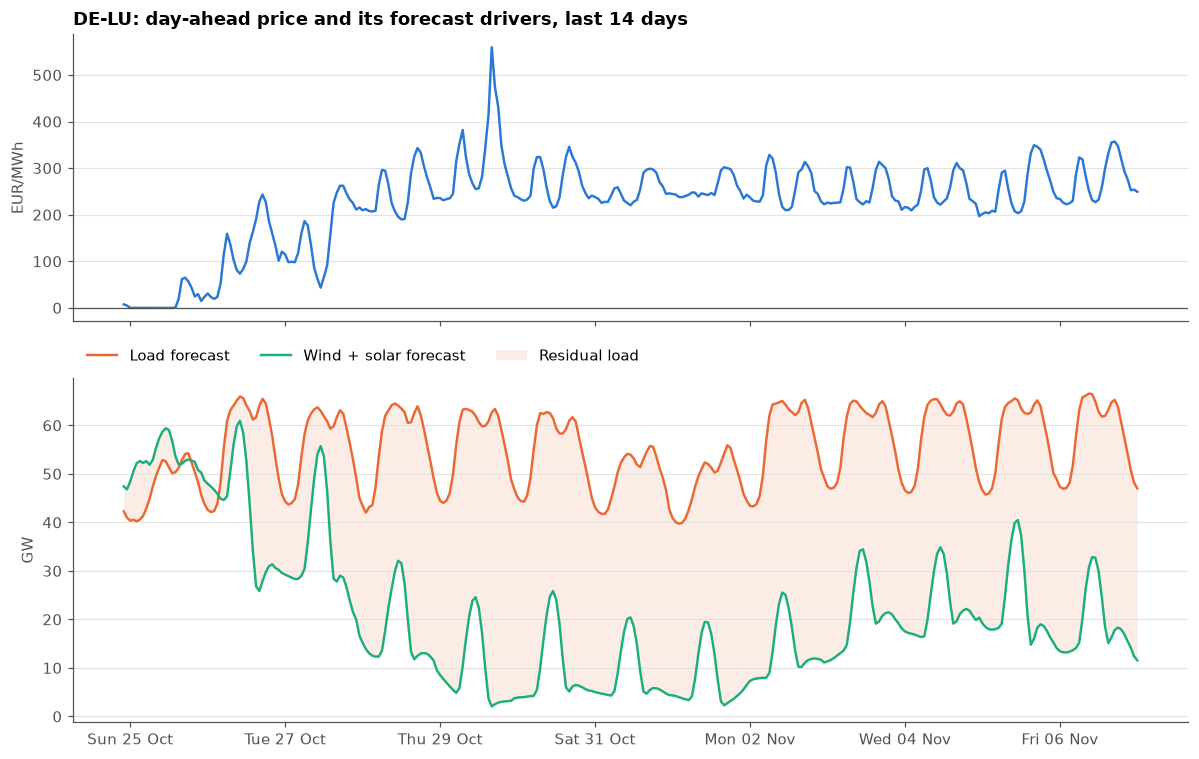

In [15]:
window = features[features.index >= now - pd.Timedelta(days=14)]

fig, (ax_price, ax_mw) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, height_ratios=[1, 1.2])
ax_price.plot(window.index, window['price'], color=BLUE)
ax_price.axhline(0, color=INK_MUTED, linewidth=0.8)
ax_price.set_ylabel('EUR/MWh')
ax_price.set_title(f'{ZONE}: day-ahead price and its forecast drivers, last 14 days')

ax_mw.plot(window.index, window['load'] / 1e3, color=SERIES_COLORS[1], label='Load forecast')
ax_mw.plot(window.index, window['wind_solar'] / 1e3, color=SERIES_COLORS[2], label='Wind + solar forecast')
ax_mw.fill_between(window.index, window['wind_solar'] / 1e3, window['load'] / 1e3,
                   color=SERIES_COLORS[1], alpha=0.12, linewidth=0, label='Residual load')
ax_mw.set_ylabel('GW')
ax_mw.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3)
ax_mw.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax_mw.xaxis.set_major_formatter(mdates.DateFormatter('%a %d %b'))
fig.tight_layout()
plt.show()

Every hour of the last year: price against residual load, with the median price per 2 GW bin.

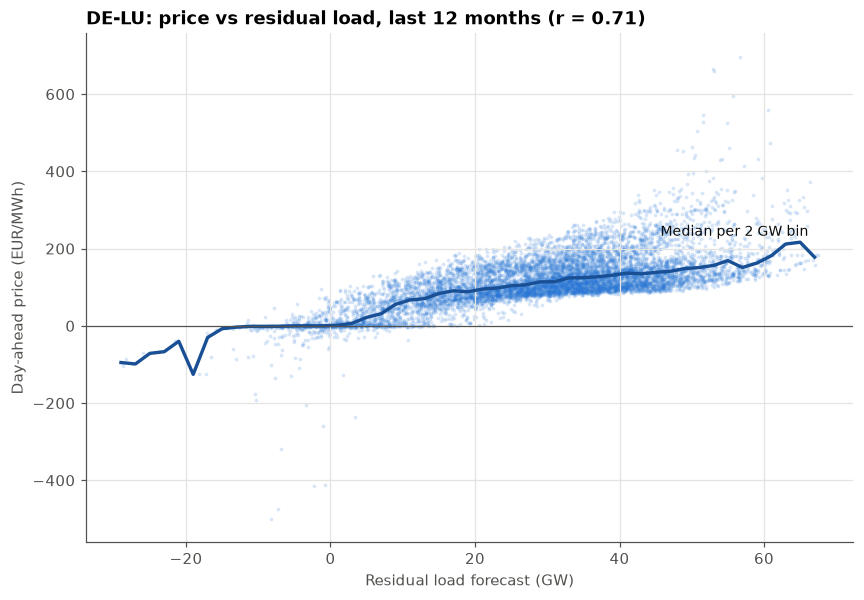

In [16]:
residual_gw = features['residual_load'] / 1e3
bins = np.arange(np.floor(residual_gw.min() / 2) * 2, residual_gw.max() + 2, 2)
binned = features['price'].groupby(pd.cut(residual_gw, bins), observed=True).median()
bin_centres = [interval.mid for interval in binned.index]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(residual_gw, features['price'], s=6, color=BLUE, alpha=0.18, linewidth=0)
ax.plot(bin_centres, binned.values, color=BLUE_DARK, linewidth=2.2)
ax.annotate('Median per 2 GW bin', (bin_centres[-1], binned.values[-1]), xytext=(-4, 14),
            textcoords='offset points', ha='right', fontsize=9, color=INK)
ax.axhline(0, color=INK_MUTED, linewidth=0.8)
ax.grid(True, axis='both')
ax.set_xlabel('Residual load forecast (GW)')
ax.set_ylabel('Day-ahead price (EUR/MWh)')
correlation = features['price'].corr(features['residual_load'])
ax.set_title(f'{ZONE}: price vs residual load, last 12 months (r = {correlation:.2f})')
plt.show()

## 6. Avoiding look-ahead

Each value carries `knowledge_time`: when it was published. A backtest that forecasts tomorrow's prices at 10:00 today must only use data known by then. `as_of` returns the data as it stood at that instant.

In [17]:
cutoff = (now - pd.Timedelta(days=1)) + pd.Timedelta(hours=10)
known = grid.values(ZONE, PRICE, provider='entsoe', start=cutoff - pd.Timedelta(days=1),
                    end=cutoff + pd.Timedelta(days=2), as_of=cutoff)
print(f'As of {cutoff:%Y-%m-%d %H:%M} UTC the latest known price interval was {known.index.max()}')
print('Publication delay ahead of delivery (hours):')
print(((known.index - known['knowledge_time']) / pd.Timedelta(hours=1)).describe().round(1).to_string())

As of 2026-11-06 10:00 UTC the latest known price interval was 2026-11-06 22:45:00+00:00
Publication delay ahead of delivery (hours):
count    148.0
mean      23.2
std        6.6
min        9.3
25%       18.5
50%       24.0
75%       28.6
max       33.1
